<a href="https://colab.research.google.com/github/angelbalderas11111/ray/blob/main/P4_PDI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Importación de librerías y carga de la imagen**

In [3]:
from google.colab import files
print("Sube tu imagen médica en escala de grises-+:")
uploaded = files.upload()

Sube tu imagen médica en escala de grises-+:


Saving rx.png to rx.png


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar la imagen en escala de grises
img = cv2.imread('rx.png', cv2.IMREAD_GRAYSCALE)

# Verificar dimensiones por si es necesario redimensionarla
print("Dimensiones de la imagen:", img.shape)

Dimensiones de la imagen: (125, 155)


**Procesamiento Geométrico (Traslación, Rotación y Escala)**

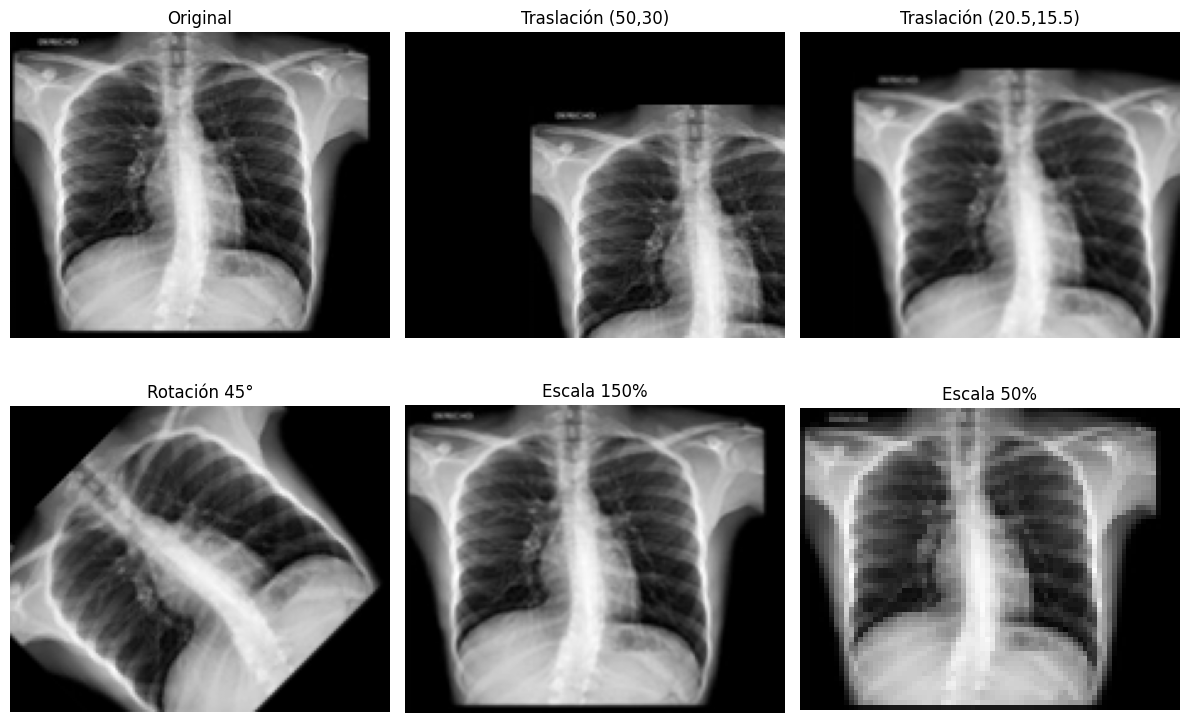

In [5]:
rows, cols = img.shape

# 1. Traslación (50, 30) y Traslación con decimales (20.5, 15.5)
M_trans1 = np.float32([[1, 0, 50], [0, 1, 30]])
img_trans1 = cv2.warpAffine(img, M_trans1, (cols, rows))

M_trans2 = np.float32([[1, 0, 20.5], [0, 1, 15.5]])
img_trans2 = cv2.warpAffine(img, M_trans2, (cols, rows))

# 2. Rotación de 45° respecto al centro
center = (cols / 2, rows / 2)
M_rot = cv2.getRotationMatrix2D(center, 45, 1.0)
img_rot = cv2.warpAffine(img, M_rot, (cols, rows))

# 3. Escalado (150% y 50%)
img_scale150 = cv2.resize(img, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_LINEAR)
img_scale50 = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_LINEAR)

# Visualización de resultados geométricos
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(img_trans1, cmap='gray')
plt.title("Traslación (50,30)")
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(img_trans2, cmap='gray')
plt.title("Traslación (20.5,15.5)")
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(img_rot, cmap='gray')
plt.title("Rotación 45°")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(img_scale150, cmap='gray')
plt.title("Escala 150%")
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(img_scale50, cmap='gray')
plt.title("Escala 50%")
plt.axis('off')

plt.tight_layout()
plt.show()

**Ecualización de Histograma**

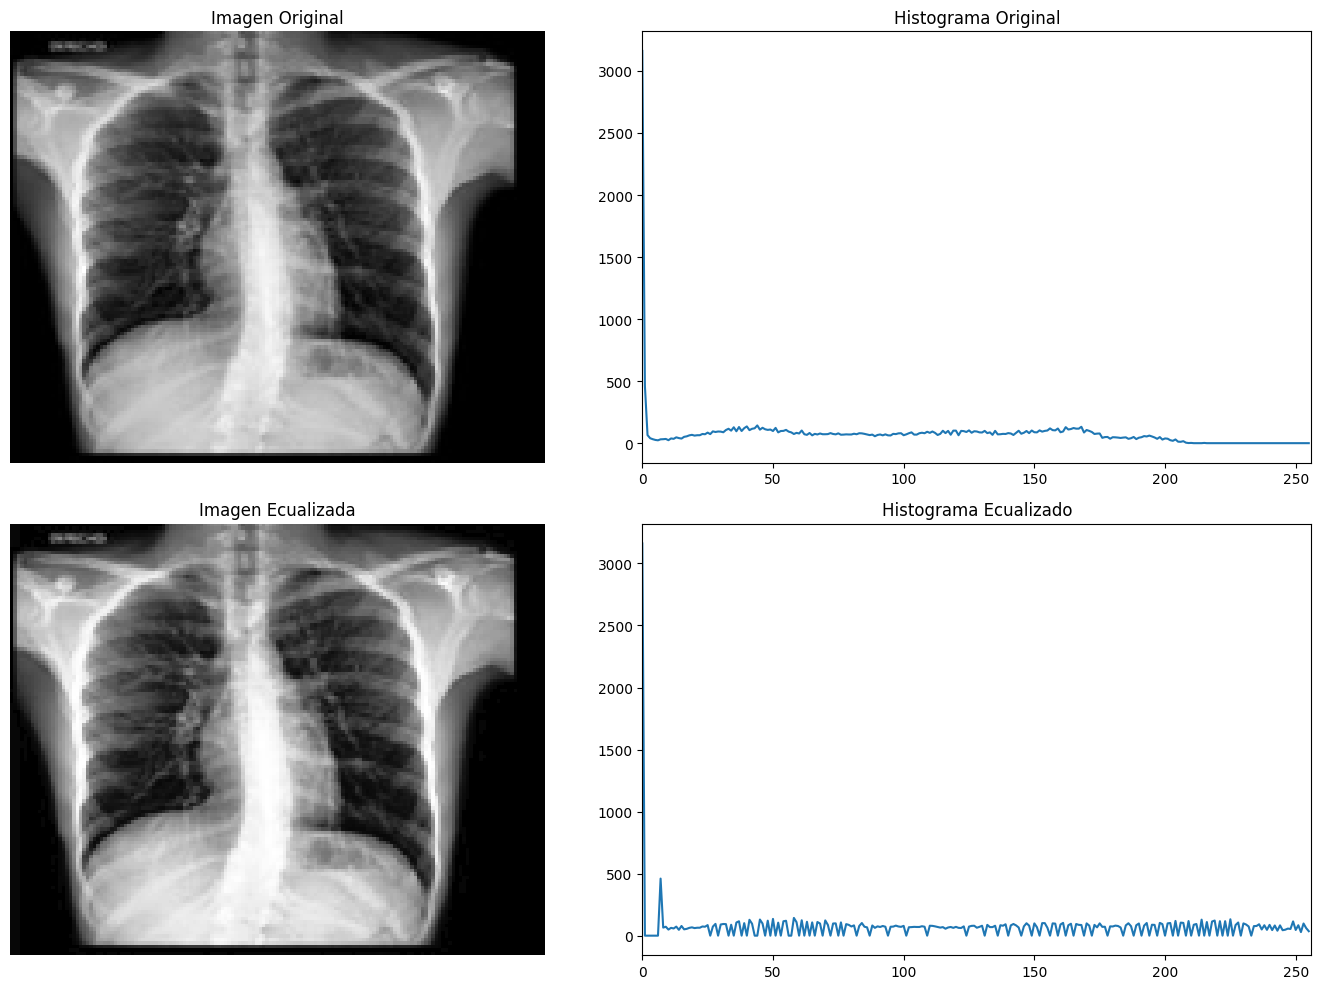

In [6]:
# Aplicar ecualización de histograma
img_eq = cv2.equalizeHist(img)

# Calcular histogramas
hist_orig = cv2.calcHist([img], [0], None, [256], [0, 256])
hist_eq = cv2.calcHist([img_eq], [0], None, [256], [0, 256])

# Visualizar resultados de ecualización e histogramas
plt.figure(figsize=(14, 10))

# 1. Imagen Original
plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Imagen Original")
plt.axis('off')

# 2. Histograma Original
plt.subplot(2, 2, 2)
plt.plot(hist_orig, color='tab:blue')
plt.title("Histograma Original")
plt.xlim([0, 256])

# 3. Imagen Ecualizada
plt.subplot(2, 2, 3)
plt.imshow(img_eq, cmap='gray')
plt.title("Imagen Ecualizada")
plt.axis('off')

# 4. Histograma Ecualizado
plt.subplot(2, 2, 4)
plt.plot(hist_eq, color='tab:blue')
plt.title("Histograma Ecualizado")
plt.xlim([0, 256])

plt.tight_layout()
plt.show()